# Paso 2: Auditoría de Calidad de Datos, Cruce con RUNT y Validación Fasecolda

En este notebook documentamos la limpieza, validación y enriquecimiento del dataset `inventario_subastas_.csv` con 350 registros, cruzandolo con `runt_vehiculos.csv` (`datos.gov.co`, dataset `aj2e-7jwg`, con 48.636 registros) y auditando la coherencia de `Valor_Fasecolda_COP`.

In [5]:
from pathlib import Path
import pandas as pd

ruta_procesado = Path("../data/processed/inventario_enriquecido.csv")
df = pd.read_csv(ruta_procesado)

print("Dimensiones del dataset enriquecido:", df.shape)
print(
    "\nSe identificaron 97 registros sin comprador asignado correspondientes a "
    "subastas 'No Adjudicadas' o 'Retiradas' con precio de venta en $0; se aíslan "
    "del calculo de ticket promedio y recuperación para evitar sesgos"
)

resumen_estados = (
    df.groupby("Estado_Subasta", dropna=False)
    .agg(
        total_vehiculos=("ID_Vehiculo", "count"),
        id_comprador_nulo=("ID_Comprador", lambda s: s.isna().sum()),
        tipo_comprador_nulo=("Tipo_Comprador", lambda s: s.isna().sum()),
        precio_venta_en_cero=("Precio_Final_Venta_COP", lambda s: (s == 0).sum()),
        precio_venta_promedio=("Precio_Final_Venta_COP", "mean"),
    )
    .reset_index()
)
display(resumen_estados)

Dimensiones del dataset enriquecido: (350, 21)

Se identificaron 97 registros sin comprador asignado correspondientes a subastas 'No Adjudicadas' o 'Retiradas' con precio de venta en $0; se aíslan del calculo de ticket promedio y recuperación para evitar sesgos


,Estado_Subasta,total_vehiculos,id_comprador_nulo,tipo_comprador_nulo,precio_venta_en_cero,precio_venta_promedio
0,No Adjudicado,81,81,81,81,0.000000e+00
1,Retirado,16,16,16,16,0.000000e+00
2,Vendido,253,0,0,0,7.931423e+07


### Hallazgo de Anomalías en Subastas ("Vendido" por debajo de "Precio_Reserva_COP")
De los **253** vehículos en estado `Vendido`, **28** se cerraron por debajo de su `Precio_Reserva_COP`. Esto sugiere flexibilización del precio de reserva al cierre para evitar re-publicar el activo, presión por antigüedad/días en inventario o negociación comercial puntual.

In [6]:
vendidos = df[df["Estado_Subasta"] == "Vendido"].copy()
vendidos["diferencia_vs_reserva"] = vendidos["Precio_Final_Venta_COP"] - vendidos["Precio_Reserva_COP"]
bajo_reserva = vendidos[vendidos["diferencia_vs_reserva"] < 0]

print(f"Total vendidos: {len(vendidos)} | Vendidos bajo reserva: {len(bajo_reserva)}")
display(
    bajo_reserva[
        [
            "ID_Vehiculo",
            "Marca",
            "Linea",
            "Estado_Vehiculo",
            "Dias_en_Inventario",
            "Canal_Asignado",
            "Precio_Reserva_COP",
            "Precio_Final_Venta_COP",
            "diferencia_vs_reserva",
        ]
    ].head(12)
)

Total vendidos: 253 | Vendidos bajo reserva: 28


,ID_Vehiculo,Marca,Linea,Estado_Vehiculo,Dias_en_Inventario,Canal_Asignado,Precio_Reserva_COP,Precio_Final_Venta_COP,diferencia_vs_reserva
1,SIM-1002,Hyundai,Tucson,Excelente,45,Subasta Virtual,99700000.0,98800000.0,-900000.0
5,SIM-1006,Toyota,Corolla,Excelente,60,Concesionario Aliado,74500000.0,73100000.0,-1400000.0
17,SIM-1018,Mazda,Mazda 3,Bueno,90,Subasta Virtual,65600000.0,64400000.0,-1200000.0
25,SIM-1026,Chevrolet,Onix,Regular,45,Subasta Virtual,42300000.0,42000000.0,-300000.0
26,SIM-1027,Renault,Duster,Regular,30,Subasta Virtual,69700000.0,68700000.0,-1000000.0
29,SIM-1030,Kia,Sportage,Excelente,45,Concesionario Aliado,96700000.0,95100000.0,-1600000.0
42,SIM-1043,Hyundai,Tucson,Excelente,15,Subasta Virtual,72900000.0,72000000.0,-900000.0
44,SIM-1045,Toyota,Hilux,Bueno,30,Subasta Virtual,145600000.0,144900000.0,-700000.0
52,SIM-1053,Chevrolet,Tracker,Bueno,30,Subasta Virtual,53300000.0,52300000.0,-1000000.0
63,SIM-1064,Toyota,Hilux,Bueno,30,Subasta Virtual,170300000.0,169600000.0,-700000.0


### Cruce con Parque Automotor ("runt_vehiculos.csv") y Validación de "Valor_Fasecolda_COP"
- **Cruce RUNT:** Se filtraron las 7 marcas del inventario sobre `runt_vehiculos.csv` (48,636 registros). Cuando una línea específica no aparece con el mismo nombre exacto en el extracto municipal (como `Mazda 3`), se documenta explícitamente y se aplica respaldo a nivel de `Marca`.
- **Validación Fasecolda:** Se revisa el comportamiento de `Valor_Fasecolda_COP` por `Marca`, `Linea` y `Modelo`. En algunas líneas aparecen medianas no estrictamente crecientes en algún año modelo debido a la mezcla de versiones, kilometraje o estado (`Excelente`, `Bueno`, `Regular`, `Siniestro Parcial`) presente en el inventario

,Marca,Linea,fuente_liquidez_mercado,conteo_runt_parque,participacion_mercado_runt_pct
6,Mazda,Mazda 3,RUNT_DatosAbiertos (Respaldo Marca),855.0,7.147037
11,Toyota,Hilux,RUNT_DatosAbiertos (Marca + Linea),276.0,2.320888
1,Chevrolet,Tracker,RUNT_DatosAbiertos (Marca + Linea),263.0,2.211571
0,Chevrolet,Onix,RUNT_DatosAbiertos (Marca + Linea),218.0,1.833165
8,Renault,Duster,RUNT_DatosAbiertos (Marca + Linea),113.0,0.950219
9,Renault,Kwid,RUNT_DatosAbiertos (Marca + Linea),109.0,0.916583
3,Kia,Picanto,RUNT_DatosAbiertos (Marca + Linea),66.0,0.554995
7,Nissan,Versa,RUNT_DatosAbiertos (Marca + Linea),61.0,0.512950
5,Mazda,CX-5,RUNT_DatosAbiertos (Marca + Linea),41.0,0.344770
4,Kia,Sportage,RUNT_DatosAbiertos (Marca + Linea),31.0,0.260679


,Marca,Linea,modelo_min,modelo_max,fasecolda_min,fasecolda_max,fasecolda_mediana
0,Chevrolet,Onix,2018,2024,44600000.0,69100000.0,55900000.0
1,Chevrolet,Tracker,2018,2024,60200000.0,94300000.0,76200000.0
2,Hyundai,Tucson,2018,2024,76600000.0,123300000.0,92300000.0
3,Kia,Picanto,2018,2024,35200000.0,53200000.0,42350000.0
4,Kia,Sportage,2018,2024,79300000.0,119800000.0,98900000.0
5,Mazda,CX-5,2018,2024,84600000.0,137000000.0,111800000.0
6,Mazda,Mazda 3,2018,2024,61100000.0,96400000.0,81800000.0
7,Nissan,Versa,2018,2024,51000000.0,72800000.0,61000000.0
8,Renault,Duster,2018,2024,62400000.0,90400000.0,73100000.0
9,Renault,Kwid,2019,2024,39200000.0,52300000.0,43100000.0


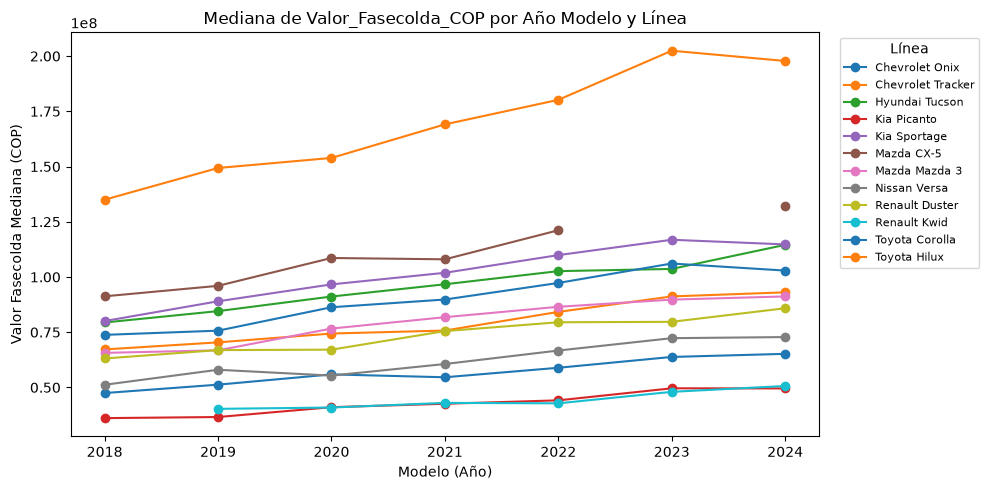

In [7]:
import matplotlib.pyplot as plt

tabla_runt = (
    df.groupby(["Marca", "Linea", "fuente_liquidez_mercado"], dropna=False)[
        ["conteo_runt_parque", "participacion_mercado_runt_pct"]
    ]
    .first()
    .reset_index()
    .sort_values("participacion_mercado_runt_pct", ascending=False)
)
display(tabla_runt)

resumen_fasecolda = (
    df.groupby(["Marca", "Linea"])
    .agg(
        modelo_min=("Modelo", "min"),
        modelo_max=("Modelo", "max"),
        fasecolda_min=("Valor_Fasecolda_COP", "min"),
        fasecolda_max=("Valor_Fasecolda_COP", "max"),
        fasecolda_mediana=("Valor_Fasecolda_COP", "median"),
    )
    .reset_index()
)
display(resumen_fasecolda)

#Grafico de validación de Valor_Fasecolda_COP por Modelo para las líneas del inventario
fig, ax = plt.subplots(figsize=(10, 5))
df["Marca_Linea"] = df["Marca"] + " " + df["Linea"]
pivot_fasecolda = df.pivot_table(
    index="Modelo",
    columns="Marca_Linea",
    values="Valor_Fasecolda_COP",
    aggfunc="median",
)
pivot_fasecolda.plot(ax=ax, marker="o")
ax.set_title("Mediana de Valor_Fasecolda_COP por Año Modelo y Línea")
ax.set_xlabel("Modelo (Año)")
ax.set_ylabel("Valor Fasecolda Mediana (COP)")
ax.legend(title="Línea", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Paso 3: Métricas de Subastas, Benchmarking, Holding Cost y Compradores

In [8]:
from pathlib import Path
import importlib.util
import sys

raiz_repo = str(Path("..").resolve())
if raiz_repo not in sys.path:
    sys.path.append(raiz_repo)

ruta_script = Path(raiz_repo) / "src" / "02_metricas_negocio.py"
spec = importlib.util.spec_from_file_location("metricas_negocio", ruta_script)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

df_m = mod.cargar_dataset_base()
df_m = mod.calcular_modulo_a_subastas(df_m)
df_m = mod.calcular_modulo_b_benchmarking_finanzas(df_m)
res_compradores = mod.calcular_modulo_c_compradores(df_m)
display(res_compradores.head(10))


MÓDULO A: ANALÍTICA DE SUBASTAS & RECUPERACIÓN DE CAPITAL
Win Rate Global: 72.29% (253 vendidos de 350 publicados)

--- Win Rate por Marca ---
    Marca  total_publicados  vehiculos_vendidos  win_rate_pct
  Renault                51                  44     86.274510
   Nissan                21                  17     80.952381
    Mazda                62                  48     77.419355
   Toyota                58                  43     74.137931
      Kia                63                  41     65.079365
  Hyundai                31                  20     64.516129
Chevrolet                64                  40     62.500000

--- Win Rate por Linea ---
   Linea  total_publicados  vehiculos_vendidos  win_rate_pct
    Kwid                24                  21     87.500000
    CX-5                27                  23     85.185185
Sportage                27                  23     85.185185
  Duster                27                  23     85.185185
   Versa                21 

,ID_Comprador,Tipo_Comprador,vehiculos_comprados,compra_total_cop,ticket_promedio_cop,margen_bruto_cop,margen_neto_ajustado_cop,es_top_20_pct,pct_acumulado_margen,pct_acumulado_volumen
0,CLI-115,Dealer / Reventa,4,440600000.0,1.101500e+08,93800000.0,85776500.0,True,3.201147,1.581028
1,CLI-147,Empresa Flotilla,5,476600000.0,9.532000e+07,79700000.0,66533000.0,True,5.921098,3.557312
2,CLI-112,Dealer / Reventa,3,367000000.0,1.223333e+08,71200000.0,61012750.0,True,8.350966,4.743083
3,CLI-148,Dealer / Reventa,5,432000000.0,8.640000e+07,69000000.0,61844250.0,True,10.705754,6.719368
4,CLI-152,Dealer / Reventa,4,328000000.0,8.200000e+07,60900000.0,53651250.0,True,12.784110,8.300395
5,CLI-135,Dealer / Reventa,4,348300000.0,8.707500e+07,58700000.0,53018000.0,True,14.787387,9.881423
6,CLI-149,Dealer / Reventa,4,335600000.0,8.390000e+07,54800000.0,48167000.0,True,16.657566,11.462451
7,CLI-118,Dealer / Reventa,5,368400000.0,7.368000e+07,54600000.0,39151500.0,True,18.520920,13.438735
8,CLI-139,Dealer / Reventa,4,359600000.0,8.990000e+07,54300000.0,49014750.0,True,20.374036,15.019763
9,CLI-102,Dealer / Reventa,3,252600000.0,8.420000e+07,53800000.0,50836750.0,True,22.210088,16.205534
